# Data Inspection — KU Leuven AAD Dataset

Inspects the structure of a raw subject `.mat` file using `inspect_mat` from `src/loading.py`.

These files are MATLAB 7.3 (HDF5-based), so `scipy.io.loadmat` can't read them — `inspect_mat` uses `h5py` instead and recursively walks structs/cell arrays, printing shapes, dtypes, and value previews.

In [1]:
import sys
from pathlib import Path

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from loading import inspect_mat

In [2]:
raw_dir = PROJECT_ROOT / "data" / "raw"
subject_files = sorted(raw_dir.glob("S*.mat"))
first_subject_file = subject_files[0]

print(f"Found {len(subject_files)} subject file(s).")
print(f"Inspecting first subject file: {first_subject_file.name}")

Found 16 subject file(s).
Inspecting first subject file: S1.mat


In [3]:
inspect_mat(first_subject_file)

Inspecting: /Users/hinrich/projects/AAD_project/data/raw/S1.mat

trials: shape=(20, 1) dtype=object matlab_class='cell'  [cell array, 20 element(s)]
  element[0]:
    element[0]: struct, fields=['FileHeader', 'RawData', 'TrialID', 'attended_ear', 'attended_track', 'condition', 'experiment', 'part', 'repetition', 'stimuli', 'subject']
      FileHeader: struct, fields=['ChannelCount', 'Channels', 'DataFormat', 'ElectrodeCap', 'FileType', 'FileTypeId', 'FileTypeNumeric', 'Gains', 'Recording', 'SampleRate', 'Subject', 'TrialID']
        ChannelCount: shape=(1, 1) dtype=float64 matlab_class='double'  value=64.0
        Channels: struct, fields=['DigitalMaximum', 'DigitalMinimum', 'Label', 'OriginalLabel', 'PhysicalDimension', 'PhysicalMaximum', 'PhysicalMinimum', 'PreFiltering', 'Reserved', 'SamplesPerRecord', 'TransducerType']
          DigitalMaximum: shape=(1, 64) dtype=object matlab_class='dataset'  [cell array, 64 element(s)]
            element[0]:
              element[0]: shape=(1, 

## Trial 0 Sanity Check — Subject 1

Loads trial 0 via `load_trial` (EEG + attended/unattended speech envelopes,
lag-corrected and resampled to the EEG rate), then plots the attended vs.
unattended envelopes for the first 30 s and EEG channel Fz for the first 5 s,
as a quick visual check that loading/alignment look right.

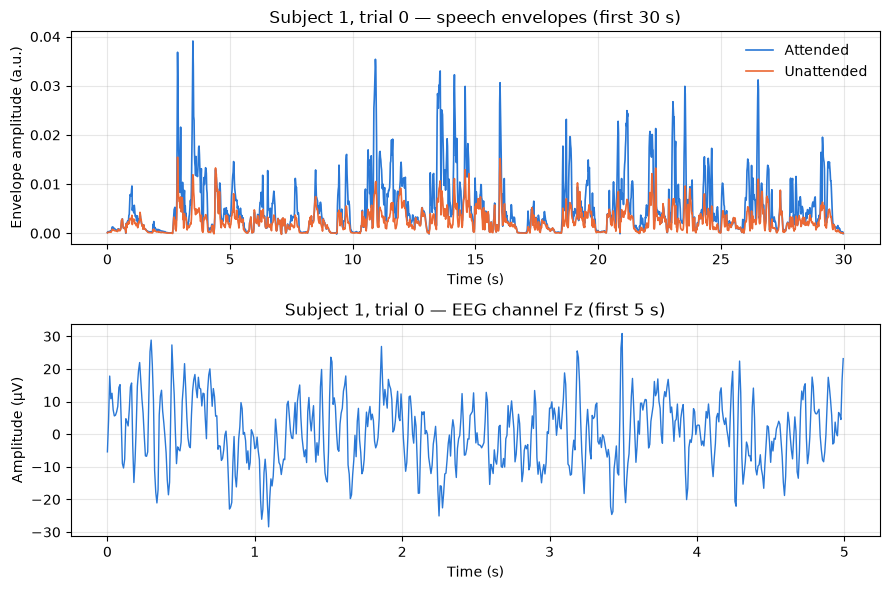

In [4]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

from loading import decode_str, load_trial

COLOR_ATTENDED = "#2a78d6"
COLOR_UNATTENDED = "#eb6834"

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

subject1_file = raw_dir / "S1.mat"
stimuli_dir = raw_dir / "stimuli"

trial0 = load_trial(subject1_file, 0, stimuli_dir)

# Channel order is the same for every trial/subject; look up Fz directly
# from this trial's FileHeader.Channels.Label rather than hardcoding it.
with h5py.File(subject1_file, "r") as f:
    trial_group = f[f["trials"][0, 0]]
    label_refs = trial_group["FileHeader"]["Channels"]["Label"][()].ravel()
    ch_names = [decode_str(f[ref][()]) for ref in label_refs]
fz_idx = ch_names.index("Fz")

fs = trial0["fs"]
env_fs = trial0["envelope_fs"]
n_env = int(30 * env_fs)
n_eeg = int(5 * fs)
t_env = np.arange(n_env) / env_fs
t_eeg = np.arange(n_eeg) / fs

fig, axes = plt.subplots(2, 1, figsize=(9, 6))

axes[0].plot(t_env, trial0["envelope_attended"][:n_env], color=COLOR_ATTENDED, lw=1.2, label="Attended")
axes[0].plot(t_env, trial0["envelope_unattended"][:n_env], color=COLOR_UNATTENDED, lw=1.2, label="Unattended")
axes[0].set_title("Subject 1, trial 0 \u2014 speech envelopes (first 30 s)")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Envelope amplitude (a.u.)")
axes[0].legend(frameon=False)
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_eeg, trial0["eeg"][fz_idx, :n_eeg], color=COLOR_ATTENDED, lw=1.0)
axes[1].set_title("Subject 1, trial 0 \u2014 EEG channel Fz (first 5 s)")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude (\u00b5V)")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "trial0_sanity_check.png", dpi=150)
plt.show()